# Data Processing

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

from utils import *

## Load Data

Load data and select features with an SQL query through the duckdb.

In [2]:
year_selected = "2026" # temporarily hardcoded df year

In [3]:
con = duckdb.connect("lol_predictors.duckdb")

df = con.execute(f"SELECT * FROM df_{year_selected}").df()

con.close()

## Feature Exclusions
Features that have zero correlations with the target feature `result` or that correlate with each other should be dropped to avoid multicollinearity.

In [4]:
# Compute correlation matrix and define the correlations of the target feature
corr_mtx = df.corr(numeric_only=True)
target_corr = corr_mtx['result'].abs()

# Find and drop features where correlation around 0.00
zero_corr_cols = target_corr[target_corr < 0.01].index.tolist()
df = df.drop(columns=zero_corr_cols, errors='ignore')

print("Dropped zero-correlation features:", zero_corr_cols)

Dropped zero-correlation features: ['ckpm']


After remove the features with zero correlations with the target feature `result`, we will have to manually remove the features that have high correlation with each other to apply domain knowledge on which of the two correlated features should retain.

In [5]:
# Adjust list based on the features considered
cols_to_drop = [
                'wardskilled'
                # All deaths stats are removed because they mirror their opps kills and assists
                'opp_deathsat10', 'opp_deathsat15', 'opp_deathsat20', 'opp_deathsat25'
                # `golddiffat15` and `xpdiffat15` surprisingly has a 0.85 corr value. 'golddiffat15' is removed because it has high collinearity with other features
                'golddiffat15',
                # Ingame stats from other timestamps does correlate past 0.80 with each other except for the 20th minute mark
                'golddiffat20', 'xpdiffat20',
                # `golddiffat25` and `xpdiffat25` has a 0.89 corr value. `xpdiffat25` is removed because gold has more impact in the late game
                'xpdiffat25'
                ]

df = df.drop(columns=cols_to_drop, errors='ignore')

Assists are not yet removed even though they have high collinearity with kills since they will be later used to calculate a support player's strength.

Also, while opponent stats also mirror with a team's stats, they will be retained to calculate "diff" features later.

## Data Imputation

Based on the EDA of `df_2026`, the missing values of the `split` feature are scattered. Since the values are chronological, we can use forward fill.

In [6]:
df['split'] = df['split'].ffill()

The features with missing values of <5% will be trimmed.

In [ ]:
# Find all columns where missingness is less than 10% (and greater than 0%)
cols_to_clean = [col for col in df.columns if 0 < df[col].isnull().mean() < 0.1]

print("Columns being cleaned for missing rows:", cols_to_clean)

# Drop rows that have NaN values in any of those specific columns
df = df.dropna(subset=cols_to_clean).reset_index(drop=True)

Columns being cleaned for missing rows: ['killsat25', 'assistsat25', 'opp_killsat25', 'opp_deathsat25', 'golddiffat25']


## Outlier Treatment

In [ ]:
# TO BE UPDATED
# num_cols = df.select_dtypes(include=["number"]).columns.tolist()

# print(num_cols)

# for col in num_cols:
#     df = df[~detect_outliers(df, col).to_numpy()]

This concludes data cleaning of `df_2026`, which is the Lol Esports data on 2026 based on Oracle's Elixir. From the EDA, there are no categories in categorical features that needs fixing. 

## Post-Processing Data Audit

In [ ]:
df.info()

In [ ]:
df.shape

In [ ]:
display(df.describe())

<Figure size 1400x800 with 0 Axes>

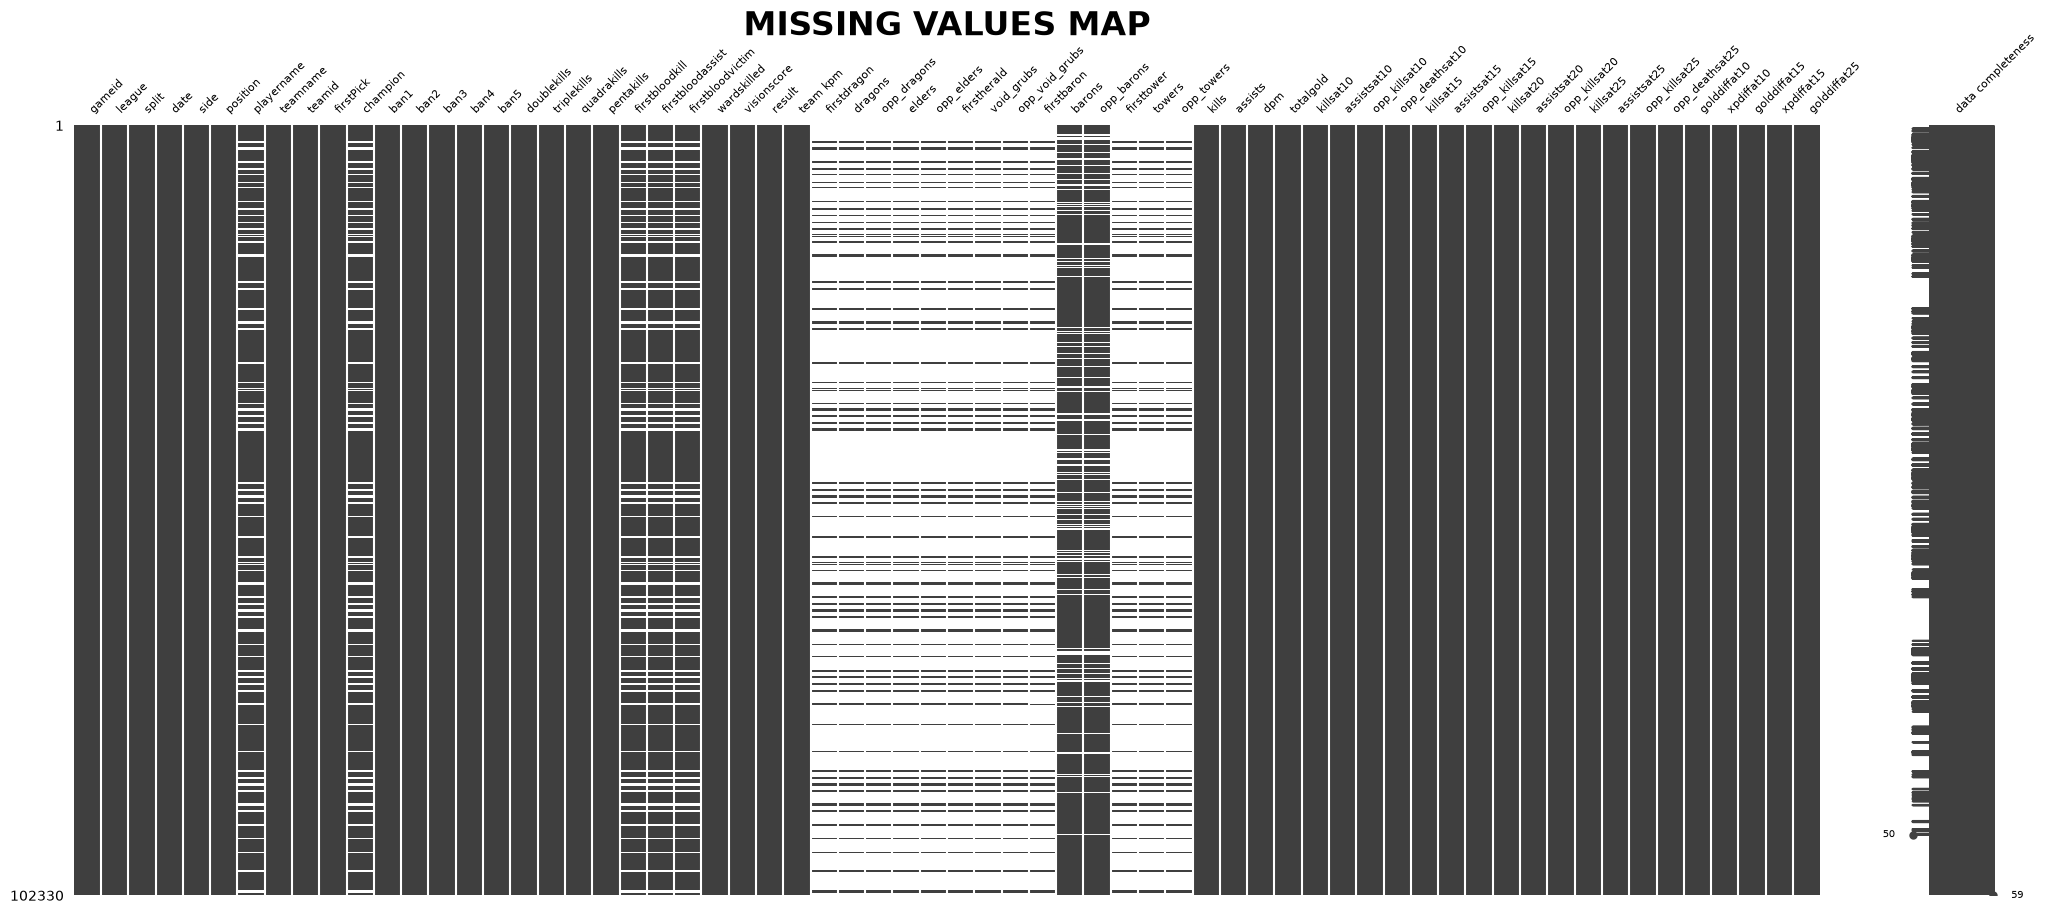


---------- PERCENTAGE OF MISSING VALUES ----------
firstbaron         83.44
opp_elders         83.33
opp_dragons        83.33
elders             83.33
dragons            83.33
void_grubs         83.33
firstherald        83.33
firstdragon        83.33
opp_void_grubs     83.33
opp_towers         83.33
firsttower         83.33
towers             83.33
firstbloodvictim   16.67
playername         16.67
firstbloodassist   16.67
champion           16.67
firstbloodkill     16.67
opp_barons         13.26
barons             13.26
dtype: float64


In [13]:
null_map(df)

The data may not look clean, but features with ~83.33% missingness are team-specific while features with ~16.67% missingness are player-specific. Player-specific features will be consolidated later, leaving team-specific features only.

In [14]:
data_profiling(df)

List of Columns: Index(['gameid', 'league', 'split', 'date', 'side', 'position', 'playername',
       'teamname', 'teamid', 'firstPick', 'champion', 'ban1', 'ban2', 'ban3',
       'ban4', 'ban5', 'doublekills', 'triplekills', 'quadrakills',
       'pentakills', 'firstbloodkill', 'firstbloodassist', 'firstbloodvictim',
       'wardskilled', 'visionscore', 'result', 'team kpm', 'firstdragon',
       'dragons', 'opp_dragons', 'elders', 'opp_elders', 'firstherald',
       'void_grubs', 'opp_void_grubs', 'firstbaron', 'barons', 'opp_barons',
       'firsttower', 'towers', 'opp_towers', 'kills', 'assists', 'dpm',
       'totalgold', 'killsat10', 'assistsat10', 'opp_killsat10',
       'opp_deathsat10', 'killsat15', 'assistsat15', 'opp_killsat15',
       'killsat20', 'assistsat20', 'opp_killsat20', 'killsat25', 'assistsat25',
       'opp_killsat25', 'opp_deathsat25', 'golddiffat10', 'xpdiffat10',
       'golddiffat15', 'xpdiffat15', 'golddiffat25'],
      dtype='str')

------------- COUNT OF U

gameid                8708
league                  42
split                   16
date                  8703
side                     2
position                 6
playername            2435
teamname               349
teamid                 350
firstPick                2
champion               171
ban1                   153
ban2                   155
ban3                   155
ban4                   158
ban5                   161
doublekills             12
triplekills              5
quadrakills              3
pentakills               3
firstbloodkill           2
firstbloodassist         2
firstbloodvictim         2
wardskilled            121
visionscore            592
result                   2
team kpm              7552
firstdragon              2
dragons                  8
opp_dragons              8
elders                   5
opp_elders               5
firstherald              2
void_grubs               5
opp_void_grubs           5
firstbaron               2
barons                   5
o


--------- UNIQUE VALUES OF OBJECT SERIES ---------

 league
LPL          6186
LCK          5892
LCKC         5634
EM           5574
LAS          4890
LEC          4518
AL           3768
LJL          3684
PRM          3684
CBLOL        3504
LCP          3312
LCS          3270
NACL         3222
LFL          3072
ROL          2832
EWC          2688
RL           2424
TCL          2358
CD           2340
HLL          2280
LIT          2274
LES          2244
HC           2214
NLC          2160
LRS          2034
EBL          1938
LRN          1830
VCS          1644
NL           1620
HM           1566
HW           1068
LPLOL         834
PCS           828
MSI           828
WSCI          804
KeSPA Cup     696
AM            684
FST           516
CCWS          456
WLDs          396
DCGI          336
AC            228
Name: count, dtype: int64

 split
Summer        23514
Spring        22674
Winter        12288
Split 2        9354
Split 1        7686
Rounds 1-2     5820
Rounds 3-4     4020
Champ 1  

In [15]:
# Limit numerical columns for description and visualization
drop_numbelow100 = [col for col in df.select_dtypes(include="number") if df[col].nunique() < 100]
drop_numbelow3 =  [col for col in df.select_dtypes(include="number") if df[col].nunique() < 3 and col != 'result']
print(drop_numbelow100)
print(drop_numbelow3)

# Limit categorical columns for description and visualization
catcols_to_drop = [col for col in df.select_dtypes(include="str") if df[col].nunique() > 50]
print(catcols_to_drop)

['firstPick', 'doublekills', 'triplekills', 'quadrakills', 'pentakills', 'firstbloodkill', 'firstbloodassist', 'firstbloodvictim', 'result', 'firstdragon', 'dragons', 'opp_dragons', 'elders', 'opp_elders', 'firstherald', 'void_grubs', 'opp_void_grubs', 'firstbaron', 'barons', 'opp_barons', 'firsttower', 'towers', 'opp_towers', 'kills', 'killsat10', 'assistsat10', 'opp_killsat10', 'opp_deathsat10', 'killsat15', 'assistsat15', 'opp_killsat15', 'killsat20', 'assistsat20', 'opp_killsat20', 'killsat25', 'assistsat25', 'opp_killsat25', 'opp_deathsat25']
['firstPick', 'firstbloodkill', 'firstbloodassist', 'firstbloodvictim', 'firstdragon', 'firstherald', 'firstbaron', 'firsttower']
['gameid', 'date', 'playername', 'teamname', 'teamid', 'champion', 'ban1', 'ban2', 'ban3', 'ban4', 'ban5']


In [16]:
count_outliers(df, drop_numbelow3)


--------------- COUNT OF OUTLIERS ----------------
doublekills:             6511 (6.36%)
triplekills:             8845 (8.64%)
quadrakills:             1565 (1.53%)
pentakills:               349 (0.34%)
wardskilled:            11935 (11.66%)
visionscore:            11000 (10.75%)
result:                     0 (0.00%)
team kpm:                 906 (0.89%)
dragons:                    1 (0.00%)
opp_dragons:                1 (0.00%)
elders:                   759 (0.74%)
opp_elders:               754 (0.74%)
void_grubs:                 0 (0.00%)
opp_void_grubs:             0 (0.00%)
barons:                 17939 (17.53%)
opp_barons:             17771 (17.37%)
towers:                     0 (0.00%)
opp_towers:                 0 (0.00%)
kills:                   8631 (8.43%)
assists:                11319 (11.06%)
dpm:                    16363 (15.99%)
totalgold:              17137 (16.75%)
killsat10:              10015 (9.79%)
assistsat10:             4252 (4.16%)
opp_killsat10:           9951

*Note that the IQR bounds are dynamically recalculated on each call. These remaining outliers are relative to the newly trimmed distribution. Since the new percentage of outliers is < 1%, it is negligible and safe to retain.*

In [ ]:
visualize_num_distribution(df, drop_numbelow100, nrows=8, ncols=4, figsize=(15, 30))

In [ ]:
# Visualization of the Splits Distribution
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='split')
plt.title('DISTRIBUTION OF SPLITS', fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.show()

In [ ]:
visualize_outliers(df, drop_numbelow3, nrows=8, ncols=4, figsize=(15, 30))

In [ ]:
# Plot correlation heatmap
plt.figure(figsize=(40, 40))
sns.heatmap(corr_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=24, fontweight="bold")
plt.show()

In [ ]:
# df.to_csv("df_processed.csv", index=False)